In [2]:
from pathlib import Path
import pandas as pd

data_folder = Path("data")

countries = {
    "US": "USvideos.csv",
    "IN": "INvideos.csv",
    "CA": "CAvideos.csv",
    "GB": "GBvideos.csv",
    "FR": "FRvideos.csv",
    "DE": "DEvideos.csv",
    "RU": "RUvideos.csv",
    "MX": "MXvideos.csv",
    "KR": "KRvideos.csv",
    "JP": "JPvideos.csv"
}

datasets = []

for country, filename in countries.items():
    file_path = data_folder / filename

    if not file_path.exists():
        print("Missing file:", file_path)
        continue

    df = pd.read_csv(file_path, encoding="utf-8", encoding_errors="replace")
    df.columns = df.columns.str.strip().str.lower()
    df = df.drop_duplicates().copy()
    df["country"] = country

    datasets.append(df)
    print(f"{country}: {len(df):,} rows")

if len(datasets) == 10:
    combined_df = pd.concat(datasets, ignore_index=True)

    Path("outputs").mkdir(exist_ok=True)
    combined_df.to_csv(
        "outputs/youtube_all_countries.csv",
        index=False
    )

    print("\nCombined shape:", combined_df.shape)
    print("\nCountry counts:")
    print(combined_df["country"].value_counts())
    print("\nCSV saved successfully!")
else:
    print("\nPlease check missing files before continuing.")

US: 40,901 rows
IN: 33,089 rows
CA: 40,881 rows
GB: 38,745 rows
FR: 40,724 rows
DE: 40,840 rows
RU: 40,693 rows
MX: 40,402 rows
KR: 32,251 rows
JP: 14,846 rows

Combined shape: (363372, 17)

Country counts:
country
US    40901
CA    40881
DE    40840
FR    40724
RU    40693
MX    40402
GB    38745
IN    33089
KR    32251
JP    14846
Name: count, dtype: int64

CSV saved successfully!


In [3]:
from pathlib import Path
import pandas as pd

# 1. Define folders and country datasets
data_folder = Path("data")
output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

countries = {
    "US": "USvideos.csv",
    "IN": "INvideos.csv",
    "CA": "CAvideos.csv",
    "GB": "GBvideos.csv",
    "FR": "FRvideos.csv",
    "DE": "DEvideos.csv",
    "RU": "RUvideos.csv",
    "MX": "MXvideos.csv",
    "KR": "KRvideos.csv",
    "JP": "JPvideos.csv"
}

datasets = []

# 2. Load and clean each country dataset
for country, filename in countries.items():
    file_path = data_folder / filename

    if not file_path.exists():
        print(f"Missing file: {file_path}")
        continue

    df = pd.read_csv(
        file_path,
        encoding="utf-8",
        encoding_errors="replace"
    )

    df.columns = df.columns.str.strip().str.lower()
    df = df.drop_duplicates().copy()

    # Standardize text columns
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for col in text_columns:
        df[col] = df[col].str.strip()

    # Convert numeric columns
    numeric_columns = [
        "category_id", "views", "likes",
        "dislikes", "comment_count"
    ]

    for col in numeric_columns:
        if col in df.columns:
            df[col] = pd.to_numeric(
                df[col], errors="coerce"
            )

    # Convert dates
    if "trending_date" in df.columns:
        df["trending_date"] = pd.to_datetime(
            df["trending_date"],
            format="%y.%d.%m",
            errors="coerce"
        )

    if "publish_time" in df.columns:
        df["publish_time"] = pd.to_datetime(
            df["publish_time"],
            errors="coerce",
            utc=True
        )

    # Fill missing descriptions
    if "description" in df.columns:
        df["description"] = df["description"].fillna("")

    # Add country identifier
    df["country"] = country
    datasets.append(df)

    print(f"{country}: {len(df):,} rows loaded")

# 3. Combine all available datasets
if len(datasets) == 10:
    combined_df = pd.concat(datasets, ignore_index=True)

    # Remove any exact duplicate rows
    combined_df = combined_df.drop_duplicates().copy()

    # 4. Save combined dataset
    output_file = output_folder / "youtube_all_countries_cleaned.csv"
    combined_df.to_csv(output_file, index=False)

    # 5. Display dataset summary
    print("\n--- DATASET SUMMARY ---")
    print("Countries loaded:", combined_df["country"].nunique())
    print("Dataset shape:", combined_df.shape)

    print("\nCountry-wise records:")
    print(combined_df["country"].value_counts())

    print("\nFirst 5 rows:")
    display(combined_df.head())

    print("\nMissing values by column:")
    print(combined_df.isnull().sum())

    print("\nTotal duplicate rows:")
    print(combined_df.duplicated().sum())

    print("\nSaved file:", output_file)

else:
    print(
        f"\nOnly {len(datasets)} of 10 datasets loaded. "
        "Check missing files before continuing."
    )

US: 40,901 rows loaded
IN: 33,089 rows loaded
CA: 40,881 rows loaded
GB: 38,745 rows loaded
FR: 40,724 rows loaded
DE: 40,840 rows loaded
RU: 40,693 rows loaded
MX: 40,402 rows loaded
KR: 32,251 rows loaded
JP: 14,846 rows loaded

--- DATASET SUMMARY ---
Countries loaded: 10
Dataset shape: (363372, 17)

Country-wise records:
country
US    40901
CA    40881
DE    40840
FR    40724
RU    40693
MX    40402
GB    38745
IN    33089
KR    32251
JP    14846
Name: count, dtype: int64

First 5 rows:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
0,2kyS6SvSYSE,2017-11-14,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13 17:13:01+00:00,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...,US
1,1ZAPwfrtAFY,2017-11-14,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13 07:30:00+00:00,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John...",US
2,5qpjK5DgCt4,2017-11-14,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12 19:05:24+00:00,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...,US
3,puqaWrEC7tY,2017-11-14,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13 11:00:04+00:00,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...,US
4,d380meD0W0M,2017-11-14,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12 18:01:41+00:00,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,US



Missing values by column:
video_id                  0
trending_date             0
title                     0
channel_title             0
category_id               0
publish_time              0
tags                      0
views                     0
likes                     0
dislikes                  0
comment_count             0
thumbnail_link            0
comments_disabled         0
ratings_disabled          0
video_error_or_removed    0
description               0
country                   0
dtype: int64

Total duplicate rows:
0

Saved file: outputs\youtube_all_countries_cleaned.csv


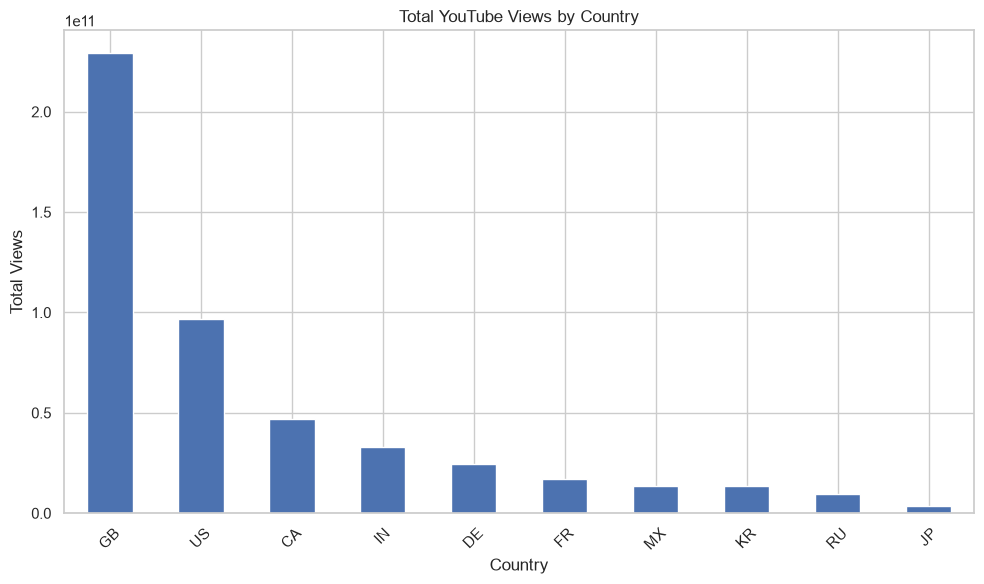

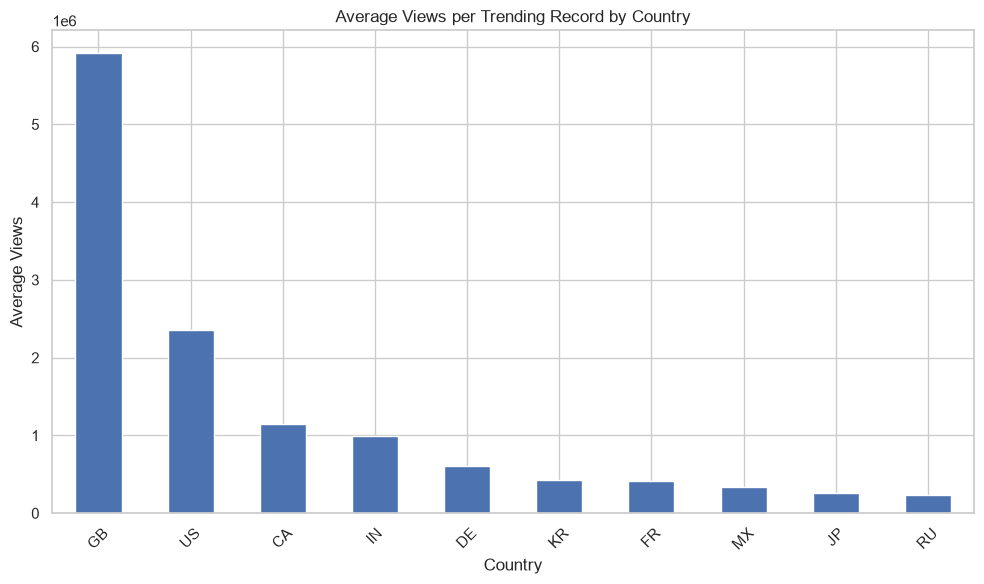

TOP 10 MOST-VIEWED VIDEO RECORDS


,title,channel_title,country,views,likes
143283,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,424538912,2818771
143083,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,413586699,2768654
142879,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,402650804,2719005
142682,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,392036878,2670723
142486,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,382401497,2618320
142295,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,372399338,2564815
142112,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,362111555,2506788
141923,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,349987176,2440754
141732,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,GB,339629489,2378829
149160,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,GB,337621571,2581961


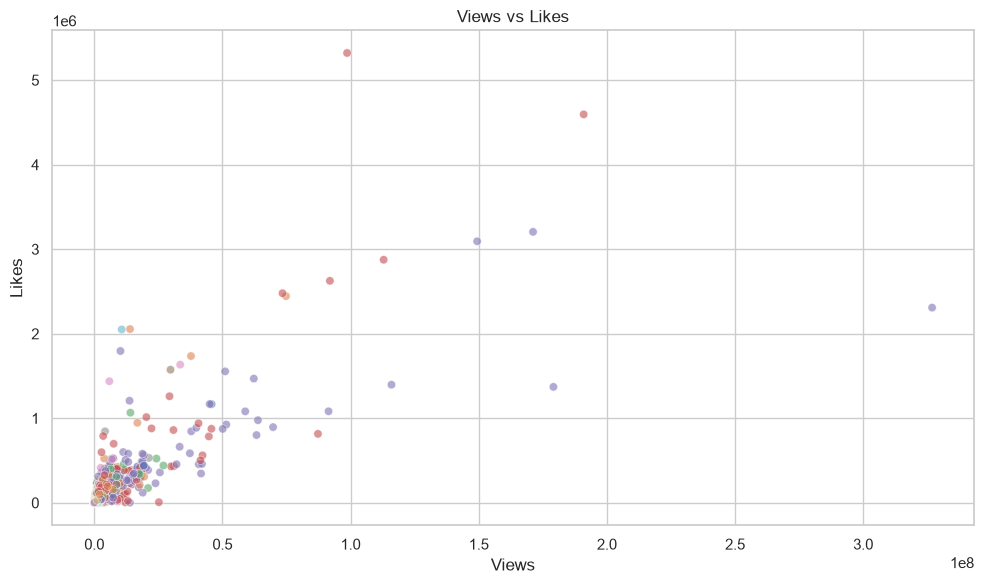


COUNTRY-WISE SUMMARY


,video_records,total_views,average_views,average_likes
country,,,,
GB,38745,229033033628,5911292.65,134467.29
US,40901,96554092462,2360678.04,74271.73
CA,40881,46891975069,1147035.91,39582.69
IN,33089,32967977200,996342.51,25587.62
DE,40840,24645115205,603455.32,21875.50
FR,40724,17100897444,419921.85,17388.86
MX,40402,13743748500,340174.95,15726.87
KR,32251,13654532085,423383.22,12059.06
RU,40693,9718024889,238813.18,12302.94



All EDA charts and summary saved in outputs/


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Load cleaned dataset
file_path = Path("outputs/youtube_all_countries_cleaned.csv")
df = pd.read_csv(file_path)

# 2. Prepare output folder
output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

# 3. Country-wise total views
country_views = (
    df.groupby("country")["views"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
country_views.plot(kind="bar")
plt.title("Total YouTube Views by Country")
plt.xlabel("Country")
plt.ylabel("Total Views")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(output_folder / "country_total_views.png")
plt.show()

# 4. Average views by country
country_avg_views = (
    df.groupby("country")["views"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
country_avg_views.plot(kind="bar")
plt.title("Average Views per Trending Record by Country")
plt.xlabel("Country")
plt.ylabel("Average Views")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(output_folder / "country_average_views.png")
plt.show()

# 5. Top 10 most-viewed video records
top_videos = df.nlargest(10, "views")[
    ["title", "channel_title", "country", "views", "likes"]
]

print("TOP 10 MOST-VIEWED VIDEO RECORDS")
display(top_videos)

# 6. Views vs likes relationship
sample_df = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sample_df,
    x="views",
    y="likes",
    hue="country",
    alpha=0.6,
    legend=False
)
plt.title("Views vs Likes")
plt.xlabel("Views")
plt.ylabel("Likes")
plt.tight_layout()
plt.savefig(output_folder / "views_vs_likes_10_countries.png")
plt.show()

# 7. Country-wise summary
summary = df.groupby("country").agg(
    video_records=("video_id", "count"),
    total_views=("views", "sum"),
    average_views=("views", "mean"),
    average_likes=("likes", "mean")
).sort_values("total_views", ascending=False)

print("\nCOUNTRY-WISE SUMMARY")
display(summary.round(2))

summary.to_csv(output_folder / "country_wise_summary.csv")

print("\nAll EDA charts and summary saved in outputs/")

In [5]:
import sqlite3
import pandas as pd
from pathlib import Path

# 1. Load cleaned dataset
df = pd.read_csv("outputs/youtube_all_countries_cleaned.csv")

# 2. Create SQLite database
Path("outputs").mkdir(exist_ok=True)

conn = sqlite3.connect("outputs/youtube_analysis.db")

# 3. Store dataset in SQL table
df.to_sql(
    "youtube_videos",
    conn,
    if_exists="replace",
    index=False
)

print("Dataset imported into SQLite successfully!")

# 4. SQL Query: Country-wise average views
query1 = """
SELECT country,
       COUNT(*) AS trending_records,
       ROUND(AVG(views), 2) AS average_views
FROM youtube_videos
GROUP BY country
ORDER BY average_views DESC;
"""

print("\n1. COUNTRY-WISE AVERAGE VIEWS")
display(pd.read_sql_query(query1, conn))

# 5. SQL Query: Top 10 records by views
query2 = """
SELECT country, title, channel_title, views, likes
FROM youtube_videos
ORDER BY views DESC
LIMIT 10;
"""

print("\n2. TOP 10 MOST-VIEWED RECORDS")
display(pd.read_sql_query(query2, conn))

# 6. SQL Query: Category-wise average views
query3 = """
SELECT country, category_id,
       COUNT(*) AS trending_records,
       ROUND(AVG(views), 2) AS average_views
FROM youtube_videos
GROUP BY country, category_id
ORDER BY average_views DESC
LIMIT 20;
"""

print("\n3. TOP COUNTRY-CATEGORY GROUPS")
display(pd.read_sql_query(query3, conn))

# 7. SQL Query: Country-wise engagement
query4 = """
SELECT country,
       ROUND(AVG(likes), 2) AS average_likes,
       ROUND(AVG(comment_count), 2) AS average_comments
FROM youtube_videos
GROUP BY country
ORDER BY average_likes DESC;
"""

print("\n4. COUNTRY-WISE ENGAGEMENT")
display(pd.read_sql_query(query4, conn))

# 8. Save SQL outputs
display(
    pd.read_sql_query(query1, conn).to_csv(
        "outputs/sql_country_analysis.csv",
        index=False
    )
)

conn.close()

print("\nSQL analysis completed!")
print("Database: outputs/youtube_analysis.db")
print("Report: outputs/sql_country_analysis.csv")

Dataset imported into SQLite successfully!

1. COUNTRY-WISE AVERAGE VIEWS


,country,trending_records,average_views
0,GB,38745,5911292.65
1,US,40901,2360678.04
2,CA,40881,1147035.91
3,IN,33089,996342.51
4,DE,40840,603455.32
5,KR,32251,423383.22
6,FR,40724,419921.85
7,MX,40402,340174.95
8,JP,14846,253701.29
9,RU,40693,238813.18



2. TOP 10 MOST-VIEWED RECORDS


,country,title,channel_title,views,likes
0,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,424538912,2818771
1,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,413586699,2768654
2,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,402650804,2719005
3,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,392036878,2670723
4,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,382401497,2618320
5,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,372399338,2564815
6,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,362111555,2506788
7,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,349987176,2440754
8,GB,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,339629489,2378829
9,GB,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,337621571,2581961



3. TOP COUNTRY-CATEGORY GROUPS


,country,category_id,trending_records,average_views
0,GB,10,13700,12439510.07
1,US,10,6467,6204776.02
2,GB,29,90,3919980.69
3,IN,20,55,3606368.82
4,CA,10,3731,3532524.84
5,GB,24,9055,3270544.71
6,GB,1,2564,3242571.39
7,IN,30,10,3191953.00
8,GB,28,516,3158529.36
9,US,1,2343,3101917.38



4. COUNTRY-WISE ENGAGEMENT


,country,average_likes,average_comments
0,GB,134467.29,13080.39
1,US,74271.73,8448.57
2,CA,39582.69,5042.97
3,IN,25587.62,2524.78
4,DE,21875.50,2785.86
5,FR,17388.86,1832.45
6,MX,15726.87,2015.97
7,RU,12302.94,1749.28
8,KR,12059.06,1971.37
9,JP,8033.44,1143.87


None


SQL analysis completed!
Database: outputs/youtube_analysis.db
Report: outputs/sql_country_analysis.csv


OVERALL TITLE SENTIMENT
title_sentiment
Neutral     349851
Positive      9482
Negative      4039
Name: count, dtype: int64


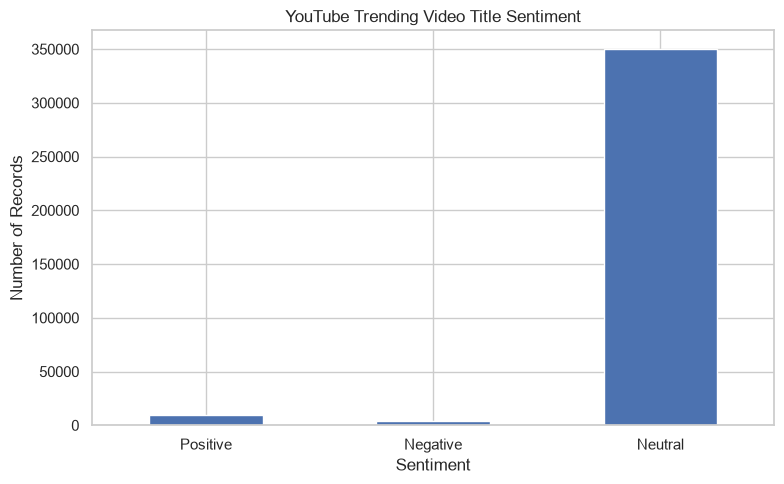


COUNTRY-WISE TITLE SENTIMENT


title_sentiment,Negative,Neutral,Positive
country,,,
CA,1029,38034,1818
DE,426,39619,795
FR,196,39882,646
GB,859,36343,1543
IN,273,31202,1614
JP,31,14601,214
KR,35,31848,368
MX,369,39593,440
RU,34,40439,220



Sentiment analysis completed!
Saved: outputs/title_sentiment.png
Saved: outputs/country_wise_sentiment.csv
Saved: outputs/youtube_sentiment_results.csv


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
import re

# 1. Load dataset
df = pd.read_csv("outputs/youtube_all_countries_cleaned.csv")

# 2. Simple word-based sentiment dictionary
positive_words = {
    "best", "love", "great", "amazing", "awesome",
    "happy", "win", "success", "beautiful", "good",
    "perfect", "fun", "wow", "incredible", "exciting"
}

negative_words = {
    "bad", "hate", "worst", "sad", "fail", "failure",
    "angry", "fake", "wrong", "terrible", "awful",
    "boring", "pain", "problem", "disaster"
}

# 3. Analyze title sentiment
def analyze_sentiment(title):
    words = re.findall(r"\b[a-zA-Z]+\b", str(title).lower())

    positive_count = sum(word in positive_words for word in words)
    negative_count = sum(word in negative_words for word in words)

    if positive_count > negative_count:
        return "Positive"
    elif negative_count > positive_count:
        return "Negative"
    else:
        return "Neutral"

df["title_sentiment"] = df["title"].apply(analyze_sentiment)

# 4. Overall sentiment counts
sentiment_counts = df["title_sentiment"].value_counts()

print("OVERALL TITLE SENTIMENT")
print(sentiment_counts)

# 5. Sentiment chart
output_folder = Path("outputs")

plt.figure(figsize=(8, 5))
sentiment_counts.reindex(
    ["Positive", "Negative", "Neutral"], fill_value=0
).plot(kind="bar")

plt.title("YouTube Trending Video Title Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_folder / "title_sentiment.png")
plt.show()

# 6. Country-wise sentiment
country_sentiment = pd.crosstab(
    df["country"], df["title_sentiment"]
)

print("\nCOUNTRY-WISE TITLE SENTIMENT")
display(country_sentiment)

country_sentiment.to_csv(
    output_folder / "country_wise_sentiment.csv"
)

# 7. Save results
df.to_csv(
    output_folder / "youtube_sentiment_results.csv",
    index=False
)

print("\nSentiment analysis completed!")
print("Saved: outputs/title_sentiment.png")
print("Saved: outputs/country_wise_sentiment.csv")
print("Saved: outputs/youtube_sentiment_results.csv")

In [7]:
import pandas as pd
import json
from pathlib import Path

# 1. Load sentiment results if available; otherwise cleaned dataset
sentiment_file = Path("outputs/youtube_sentiment_results.csv")
cleaned_file = Path("outputs/youtube_all_countries_cleaned.csv")

if sentiment_file.exists():
    df = pd.read_csv(sentiment_file)
else:
    df = pd.read_csv(cleaned_file)

# 2. Find category JSON files
archive_folder = Path("archive")
category_folder = Path("data")

category_names = {}

for country in ["US", "IN", "CA", "GB", "FR",
                "DE", "RU", "MX", "KR", "JP"]:

    json_file = archive_folder / f"{country}_category_id.json"

    if not json_file.exists():
        json_file = category_folder / f"{country}_category_id.json"

    if not json_file.exists():
        print(f"Category JSON not found for {country}")
        continue

    with open(json_file, "r", encoding="utf-8") as file:
        category_data = json.load(file)

    for item in category_data.get("items", []):
        category_id = item.get("id")
        category_title = item.get("snippet", {}).get("title")

        if category_id is not None and category_title:
            category_names[(country, str(category_id))] = category_title

# 3. Map category IDs using each country's mapping
df["category_name"] = df.apply(
    lambda row: category_names.get(
        (row["country"], str(int(row["category_id"]))
         if pd.notna(row["category_id"]) else ""),
        "Unknown"
    ),
    axis=1
)

# 4. Display category mapping results
print("CATEGORY MAPPING SAMPLE")
display(df[["country", "category_id", "category_name"]].head(10))

print("\nTop categories by record count:")
display(
    df["category_name"]
    .value_counts()
    .head(15)
    .rename_axis("category_name")
    .reset_index(name="record_count")
)

# 5. Save mapped dataset
output_file = Path("outputs/youtube_category_mapped.csv")
df.to_csv(output_file, index=False)

print("\nCategory mapping completed!")
print("Saved:", output_file)

Category JSON not found for US
Category JSON not found for IN
Category JSON not found for CA
Category JSON not found for GB
Category JSON not found for FR
Category JSON not found for DE
Category JSON not found for RU
Category JSON not found for MX
Category JSON not found for KR
Category JSON not found for JP
CATEGORY MAPPING SAMPLE


,country,category_id,category_name
0,US,22,Unknown
1,US,24,Unknown
2,US,23,Unknown
3,US,24,Unknown
4,US,24,Unknown
5,US,28,Unknown
6,US,24,Unknown
7,US,28,Unknown
8,US,1,Unknown
9,US,25,Unknown



Top categories by record count:


,category_name,record_count
0,Unknown,363372



Category mapping completed!
Saved: outputs\youtube_category_mapped.csv


In [8]:
import pandas as pd
from pathlib import Path

input_file = Path("outputs/youtube_all_countries_cleaned.csv")
output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

df = pd.read_csv(input_file, encoding="utf-8",
                 encoding_errors="replace")

# Standardize column names and text values
df.columns = df.columns.str.strip().str.lower()

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# Convert numeric columns
for col in ["category_id", "views", "likes",
            "dislikes", "comment_count"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert date columns
df["trending_date"] = pd.to_datetime(
    df["trending_date"], errors="coerce"
)
df["publish_time"] = pd.to_datetime(
    df["publish_time"], errors="coerce", utc=True
)

# Report duplicates and missing values before final handling
print("Dataset shape:", df.shape)
print("\nCountry counts:")
print(df["country"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Save standardized data
df.to_csv(
    output_folder / "youtube_all_countries_standardized.csv",
    index=False
)

print("\nStandardized dataset saved successfully!")
print("Final shape:", df.shape)

Dataset shape: (363372, 17)

Country counts:
country
US    40901
CA    40881
DE    40840
FR    40724
RU    40693
MX    40402
GB    38745
IN    33089
KR    32251
JP    14846
Name: count, dtype: int64

Missing values:
video_id                      0
trending_date                 0
title                         0
channel_title                 0
category_id                   0
publish_time                  0
tags                          0
views                         0
likes                         0
dislikes                      0
comment_count                 0
thumbnail_link                0
comments_disabled             0
ratings_disabled              0
video_error_or_removed        0
description               18697
country                       0
dtype: int64

Exact duplicate rows: 0

Standardized dataset saved successfully!
Final shape: (363372, 17)


TITLE SENTIMENT COUNTS
title_sentiment
Neutral     348353
Positive     10936
Negative      4083
Name: count, dtype: int64

TAGS SENTIMENT COUNTS
tags_sentiment
Neutral     322939
Positive     32009
Negative      8424
Name: count, dtype: int64

COUNTRY-WISE TITLE SENTIMENT


title_sentiment,Negative,Neutral,Positive
country,,,
CA,1047,37802,2032
DE,430,39555,855
FR,198,39833,693
GB,846,35853,2046
IN,295,31094,1700
JP,34,14567,245
KR,34,31820,397
MX,381,39543,478
RU,30,40411,252


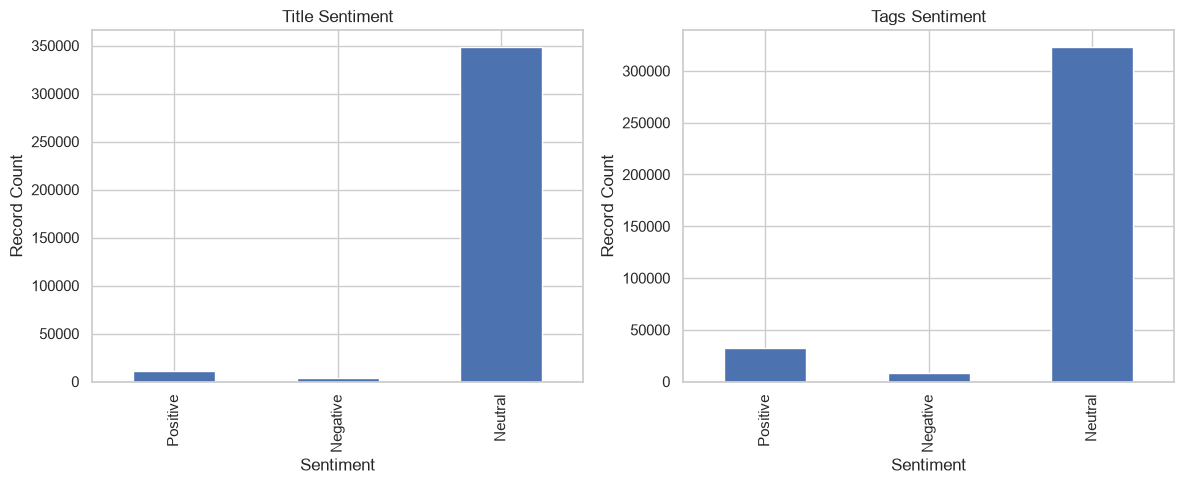


Sentiment analysis completed!
Saved: outputs/youtube_title_tags_sentiment.csv
Saved: outputs/title_tags_sentiment.png


In [9]:
import pandas as pd
import re
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Load standardized dataset
df = pd.read_csv(
    "outputs/youtube_all_countries_standardized.csv"
)

# 2. Basic sentiment word lists
positive_words = {
    "best", "love", "great", "amazing", "awesome",
    "happy", "win", "success", "beautiful", "good",
    "perfect", "fun", "wow", "incredible", "exciting",
    "like", "enjoy", "wonderful", "excellent"
}

negative_words = {
    "bad", "hate", "worst", "sad", "fail", "failure",
    "angry", "fake", "wrong", "terrible", "awful",
    "boring", "pain", "problem", "disaster", "poor",
    "dislike", "annoying", "horrible"
}

# 3. Function to classify text
def get_sentiment(text):
    words = re.findall(r"[a-zA-Z]+", str(text).lower())
    positive = sum(word in positive_words for word in words)
    negative = sum(word in negative_words for word in words)

    if positive > negative:
        return "Positive"
    elif negative > positive:
        return "Negative"
    else:
        return "Neutral"

# 4. Analyze titles
df["title_sentiment"] = df["title"].fillna("").apply(get_sentiment)

# 5. Analyze tags
df["tags_sentiment"] = df["tags"].fillna("").apply(get_sentiment)

# 6. Overall title sentiment
print("TITLE SENTIMENT COUNTS")
print(df["title_sentiment"].value_counts())

# 7. Overall tags sentiment
print("\nTAGS SENTIMENT COUNTS")
print(df["tags_sentiment"].value_counts())

# 8. Compare sentiment by country
country_sentiment = pd.crosstab(
    df["country"], df["title_sentiment"]
)

print("\nCOUNTRY-WISE TITLE SENTIMENT")
display(country_sentiment)

# 9. Plot title and tags sentiment
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df["title_sentiment"].value_counts().reindex(
    ["Positive", "Negative", "Neutral"], fill_value=0
).plot(kind="bar", ax=axes[0], title="Title Sentiment")

df["tags_sentiment"].value_counts().reindex(
    ["Positive", "Negative", "Neutral"], fill_value=0
).plot(kind="bar", ax=axes[1], title="Tags Sentiment")

axes[0].set_xlabel("Sentiment")
axes[1].set_xlabel("Sentiment")
axes[0].set_ylabel("Record Count")
axes[1].set_ylabel("Record Count")

plt.tight_layout()
Path("outputs").mkdir(exist_ok=True)
plt.savefig("outputs/title_tags_sentiment.png")
plt.show()

# 10. Save results
df.to_csv(
    "outputs/youtube_title_tags_sentiment.csv",
    index=False
)

country_sentiment.to_csv(
    "outputs/country_title_sentiment.csv"
)

print("\nSentiment analysis completed!")
print("Saved: outputs/youtube_title_tags_sentiment.csv")
print("Saved: outputs/title_tags_sentiment.png")

In [10]:
import sqlite3
import pandas as pd
from pathlib import Path

# 1. Connect to existing SQL database
db_path = "outputs/youtube_analysis.db"
conn = sqlite3.connect(db_path)

# 2. Check available tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)
print("Available SQL tables:")
display(tables)

# 3. Rank categories by average views
query = """
SELECT
    category_id,
    COUNT(*) AS trending_records,
    ROUND(AVG(views), 2) AS average_views,
    RANK() OVER (ORDER BY AVG(views) DESC) AS category_rank
FROM youtube_videos
WHERE views IS NOT NULL
  AND category_id IS NOT NULL
GROUP BY category_id
ORDER BY category_rank;
"""

ranking = pd.read_sql_query(query, conn)

print("\nCATEGORY RANKING BY AVERAGE VIEWS")
display(ranking)

# 4. Save results
output_path = Path("outputs/category_average_views_ranking.csv")
ranking.to_csv(output_path, index=False)

conn.close()

print("\nSQL category ranking completed!")
print("Saved:", output_path)

Available SQL tables:


,name
0,youtube_videos



CATEGORY RANKING BY AVERAGE VIEWS


,category_id,trending_records,average_views,category_rank
0,10,41454,6094538.06,1
1,30,30,1774642.90,2
2,1,20193,1327032.46,3
3,28,8068,1115871.45,4
4,24,104567,963506.53,5
5,23,26077,820326.99,6
6,17,23035,807818.68,7
7,20,11063,681813.36,8
8,26,18554,520409.15,9
9,43,909,443009.15,10



SQL category ranking completed!
Saved: outputs\category_average_views_ranking.csv


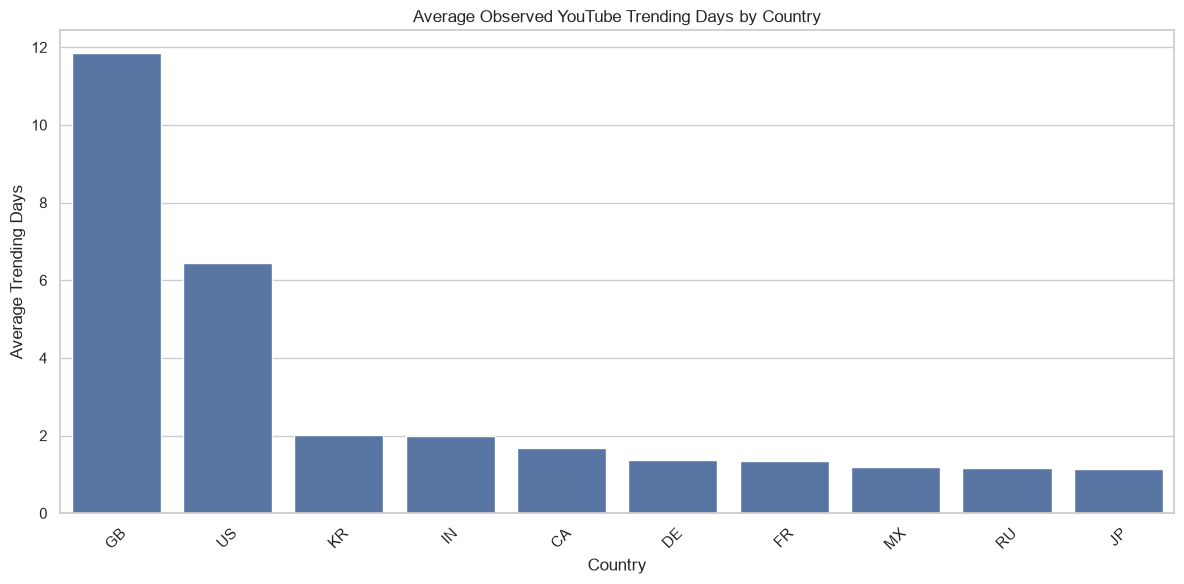

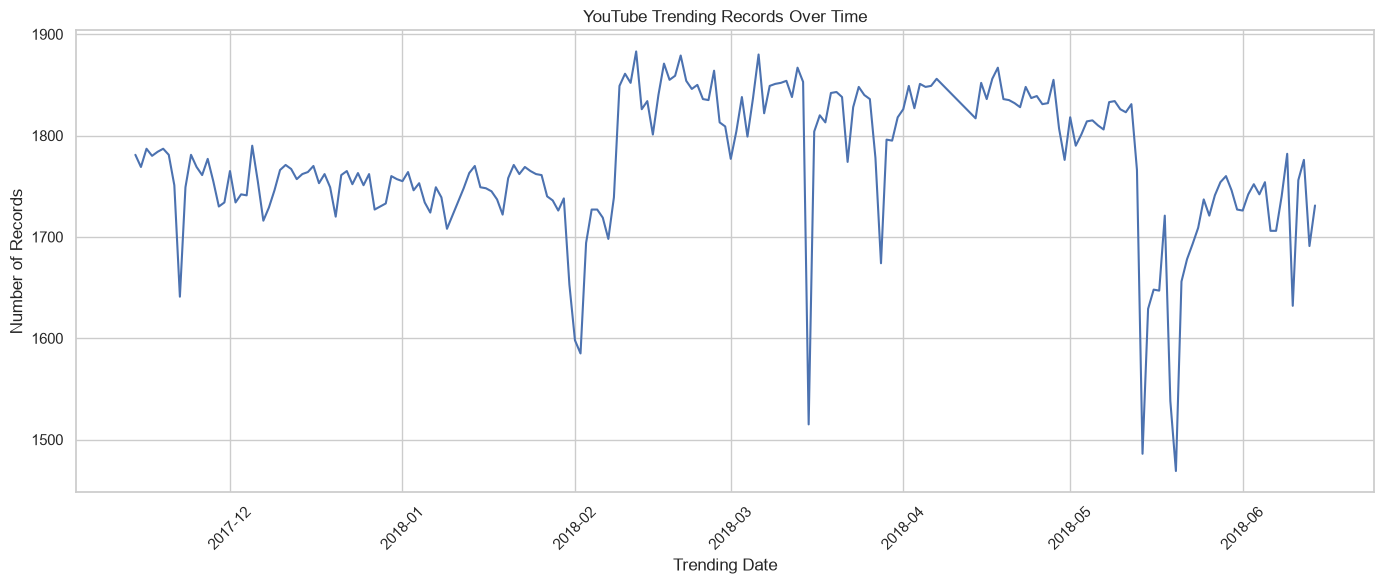

Trending duration analysis completed!
Saved: outputs/video_trending_duration.csv
Saved: outputs/trending_duration_by_country.png
Saved: outputs/trending_records_over_time.png


,country,trending_days
0,GB,11.840465
1,US,6.439773
2,KR,2.011968
3,IN,1.990434
4,CA,1.673599
5,DE,1.378472
6,FR,1.331677
7,MX,1.195745
8,RU,1.176186
9,JP,1.126317


,country,video_id,first_trending_date,last_trending_date,trending_days
0,CA,--45ws7CEN0,2018-06-12,2018-06-12,1
1,CA,--7vNbh4UNA,2018-04-14,2018-04-16,3
2,CA,--MtKsH5oBY,2018-06-01,2018-06-01,1
3,CA,--YgtVuvWGo,2018-05-20,2018-05-20,1
4,CA,--iJShLChIc,2018-05-01,2018-05-01,1


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the standardized dataset
file_path = Path("outputs/youtube_all_countries_standardized.csv")

df = pd.read_csv(file_path, encoding="utf-8", encoding_errors="replace")

# Convert dates
df["trending_date"] = pd.to_datetime(
    df["trending_date"], errors="coerce"
)

# Remove rows without required values
df = df.dropna(subset=["video_id", "trending_date", "country"])

# Calculate observed trending duration for each video
video_duration = (
    df.groupby(["country", "video_id"])["trending_date"]
    .agg(
        first_trending_date="min",
        last_trending_date="max",
        trending_days="nunique"
    )
    .reset_index()
)

# Save results
output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

video_duration.to_csv(
    output_folder / "video_trending_duration.csv",
    index=False
)

# Chart 1: Average observed trending days by country
country_duration = (
    video_duration.groupby("country")["trending_days"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=country_duration,
    x="country",
    y="trending_days"
)
plt.title("Average Observed YouTube Trending Days by Country")
plt.xlabel("Country")
plt.ylabel("Average Trending Days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    output_folder / "trending_duration_by_country.png",
    dpi=300
)
plt.show()

# Chart 2: Number of trending records over time
daily_records = (
    df.groupby("trending_date")
    .size()
    .reset_index(name="trending_records")
    .sort_values("trending_date")
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=daily_records,
    x="trending_date",
    y="trending_records"
)
plt.title("YouTube Trending Records Over Time")
plt.xlabel("Trending Date")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    output_folder / "trending_records_over_time.png",
    dpi=300
)
plt.show()

print("Trending duration analysis completed!")
print("Saved: outputs/video_trending_duration.csv")
print("Saved: outputs/trending_duration_by_country.png")
print("Saved: outputs/trending_records_over_time.png")

display(country_duration)
display(video_duration.head())

In [12]:
import pandas as pd

df = pd.read_csv(
    "outputs/youtube_title_tags_sentiment.csv",
    encoding="utf-8",
    encoding_errors="replace"
)

sample = df.sample(
    n=min(20000, len(df)),
    random_state=42
)

sample.to_csv(
    "outputs/youtube_tableau_sample.csv",
    index=False
)

print("Sample created!")
print("Rows:", len(sample))
print("File size (MB):",
      round(
          __import__("os").path.getsize(
              "outputs/youtube_tableau_sample.csv"
          ) / (1024 * 1024), 2
      ))

Sample created!
Rows: 20000
File size (MB): 27.98


In [13]:
import pandas as pd

df = pd.read_csv(
    "outputs/youtube_title_tags_sentiment.csv",
    encoding="utf-8",
    encoding_errors="replace"
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nSentiment-related columns:")
print([
    col for col in df.columns
    if "sentiment" in col.lower()
])

Dataset shape: (363372, 19)

Column names:
['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country', 'title_sentiment', 'tags_sentiment']

First 5 rows:


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country,title_sentiment,tags_sentiment
0,2kyS6SvSYSE,2017-11-14,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13 17:13:01+00:00,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...,US,Neutral,Neutral
1,1ZAPwfrtAFY,2017-11-14,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13 07:30:00+00:00,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John...",US,Neutral,Neutral
2,5qpjK5DgCt4,2017-11-14,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12 19:05:24+00:00,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...,US,Neutral,Positive
3,puqaWrEC7tY,2017-11-14,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13 11:00:04+00:00,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...,US,Negative,Positive
4,d380meD0W0M,2017-11-14,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12 18:01:41+00:00,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,US,Neutral,Negative



Sentiment-related columns:
['title_sentiment', 'tags_sentiment']


In [14]:
import pandas as pd

file_path = "outputs/category_average_views_ranking.csv"
df = pd.read_csv(file_path)

print("SQL Category Ranking")
print("Rows and columns:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head(10))

SQL Category Ranking
Rows and columns: (18, 4)

Available columns:
['category_id', 'trending_records', 'average_views', 'category_rank']


,category_id,trending_records,average_views,category_rank
0,10,41454,6094538.06,1
1,30,30,1774642.90,2
2,1,20193,1327032.46,3
3,28,8068,1115871.45,4
4,24,104567,963506.53,5
5,23,26077,820326.99,6
6,17,23035,807818.68,7
7,20,11063,681813.36,8
8,26,18554,520409.15,9
9,43,909,443009.15,10


In [15]:
import pandas as pd

file_path = "outputs/youtube_title_tags_sentiment.csv"

df = pd.read_csv(
    file_path,
    encoding="utf-8",
    encoding_errors="replace"
)

print("Dataset shape:", df.shape)
print("\nAll columns:")
print(df.columns.tolist())

print("\nSentiment columns:")
print([
    col for col in df.columns
    if "sentiment" in col.lower()
])

display(df.head(5))

Dataset shape: (363372, 19)

All columns:
['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country', 'title_sentiment', 'tags_sentiment']

Sentiment columns:
['title_sentiment', 'tags_sentiment']


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country,title_sentiment,tags_sentiment
0,2kyS6SvSYSE,2017-11-14,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13 17:13:01+00:00,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...,US,Neutral,Neutral
1,1ZAPwfrtAFY,2017-11-14,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13 07:30:00+00:00,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John...",US,Neutral,Neutral
2,5qpjK5DgCt4,2017-11-14,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12 19:05:24+00:00,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...,US,Neutral,Positive
3,puqaWrEC7tY,2017-11-14,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13 11:00:04+00:00,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...,US,Negative,Positive
4,d380meD0W0M,2017-11-14,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12 18:01:41+00:00,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,US,Neutral,Negative
